In [70]:
import pandas as pd

df = pd.read_parquet("dataset_limpio.parquet")

print(df.columns.tolist())
df.info()

['product_name', 'brands', 'categories', 'ingredients', 'nova_group', 'allergens', 'energy_kcal', 'fat_100g', 'saturated_fat_100g', 'carbs_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'contains_gluten', 'contains_dairy', 'contains_nuts', 'contains_soy', 'contains_eggs', 'contains_fish', 'nutriscore_num', 'ecoscore_num', 'categoria_macro']
<class 'pandas.DataFrame'>
RangeIndex: 4686 entries, 0 to 4685
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_name        4570 non-null   str    
 1   brands              4563 non-null   str    
 2   categories          4661 non-null   str    
 3   ingredients         4601 non-null   str    
 4   nova_group          4365 non-null   Int8   
 5   allergens           3286 non-null   str    
 6   energy_kcal         4686 non-null   float64
 7   fat_100g            4686 non-null   float64
 8   saturated_fat_100g  4686 non-nul

### Empezaremos viendo posibles correlaciones lineales entre las variables 

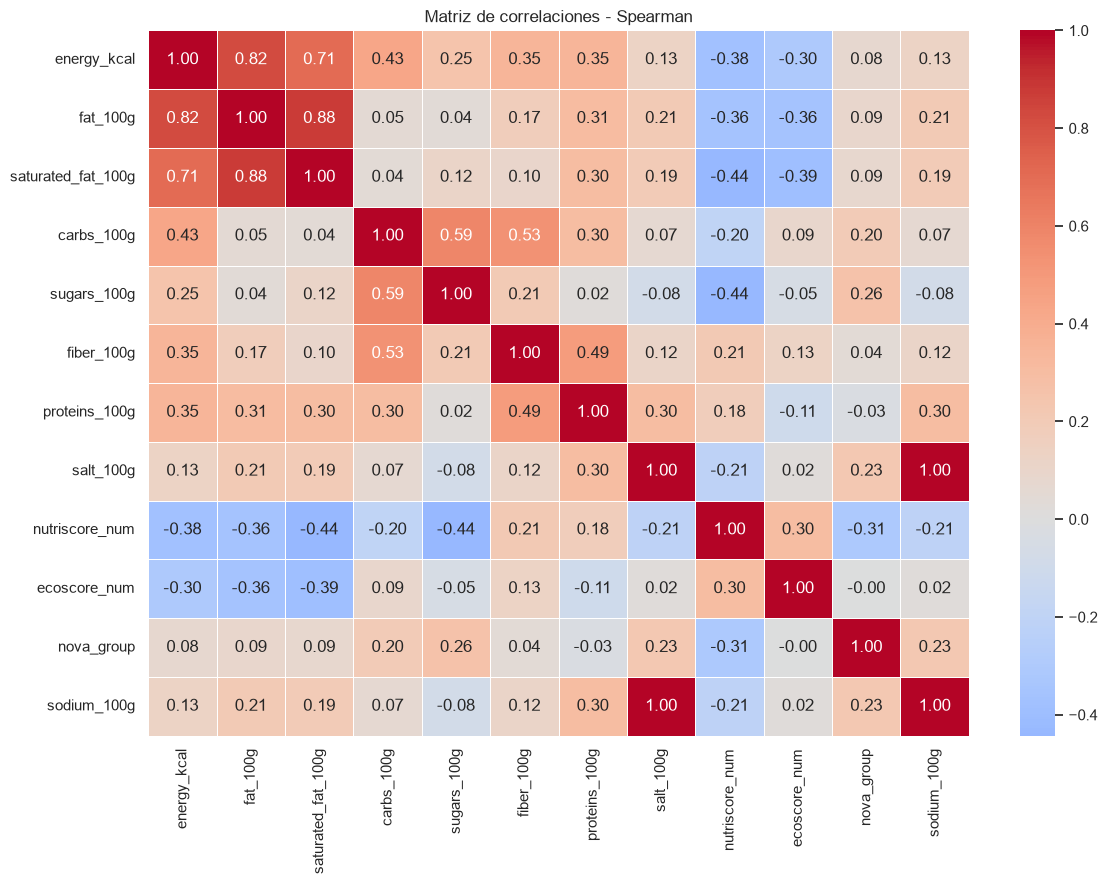

---- spearman -----
     Variable_1          Variable_2  Correlacion
95    salt_100g         sodium_100g     0.999999
14     fat_100g  saturated_fat_100g     0.880271
1   energy_kcal            fat_100g     0.824615
2   energy_kcal  saturated_fat_100g     0.706606


In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

variables_corr = [
    'energy_kcal',
    'fat_100g',
    'saturated_fat_100g',
    'carbs_100g',
    'sugars_100g',
    'fiber_100g',
    'proteins_100g',
    'salt_100g',
    'nutriscore_num',
    'ecoscore_num',
    'nova_group',
    'sodium_100g'
]

corr_spearman = df[variables_corr].corr(method='spearman')
corr_pearson = df[variables_corr].corr(method='pearson')

# Extraer el triángulo superior de la matriz para evitar pares duplicados (A-B y B-A) y la diagonal (A-A)
upper_tri_spearman = corr_spearman.where(np.triu(np.ones(corr_spearman.shape), k=1).astype(bool))

# Convertir a formato tabla
corr_pairs_spearman = upper_tri_spearman.stack().reset_index()
corr_pairs_spearman.columns = ['Variable_1', 'Variable_2', 'Correlacion']

# Filtrar por valor absoluto > 0.75 y ordenar
high_corr_spearman = corr_pairs_spearman[corr_pairs_spearman['Correlacion'].abs() > 0.70].sort_values(by='Correlacion', key=abs, ascending=False)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de correlaciones - Spearman')
plt.tight_layout()
plt.show()


print("---- spearman -----")
print(high_corr_spearman)

### Podemos observar que el sodio y las sales van muy de la mano, al igual que las grasas y las grasas saturadas. Esto es información redundante que solo añade ruido al modelo, por lo que solo tendremos en cuenta sales y grasas

In [73]:
# Strip standard whitespace and hidden unicode spaces
df.columns = df.columns.str.replace("\xa0", "").str.strip()

# Drop the target columns
df = df.drop(["sodium_100g", "saturated_fat_100g"], axis=1, errors="ignore")

## Procederemos a hacer un PCA para poder analizar relaciones en una menor dimension, entre nuestras nuevas 7 variables de estudio

In [74]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

variables_pca = [
    'energy_kcal',
    'fat_100g',
    'carbs_100g',
    'sugars_100g',
    'fiber_100g',
    'proteins_100g',
    'salt_100g',
]

df_pca = df[variables_pca].dropna().copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca)

pca = PCA(n_components=5)
componentes = pca.fit_transform(X_scaled)

varianza_explicada = pca.explained_variance_ratio_

print('Varianza explicada por componente:')
print(varianza_explicada)

print('\nVarianza acumulada:')
print(varianza_explicada.cumsum())

Varianza explicada por componente:
[0.30485114 0.21546055 0.18312877 0.14069598 0.09085   ]

Varianza acumulada:
[0.30485114 0.52031169 0.70344047 0.84413644 0.93498645]


In [75]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=variables_pca,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
)

print(loadings)

                    PC1       PC2       PC3       PC4       PC5
energy_kcal    0.612690  0.249240 -0.196550  0.083672  0.002384
fat_100g       0.386515  0.557092 -0.369735  0.017721 -0.097014
carbs_100g     0.440599 -0.527691  0.070092  0.083336  0.028998
sugars_100g    0.319719 -0.538800 -0.320066  0.060534  0.228612
fiber_100g     0.331313 -0.043039  0.586738 -0.017463 -0.665913
proteins_100g  0.236013  0.235312  0.609993  0.026487  0.701413
salt_100g     -0.115752  0.039254  0.030915  0.990489 -0.045375


### Vemos que la combinación lineal de los 3 primeros componentes esta muy distrubuida entre varias variables y recien con 4 componentes llegamos a una buena cifra de varianza explicada; y además esta 4ta componente esta prácticamente explicada por el coeficiente de las sales

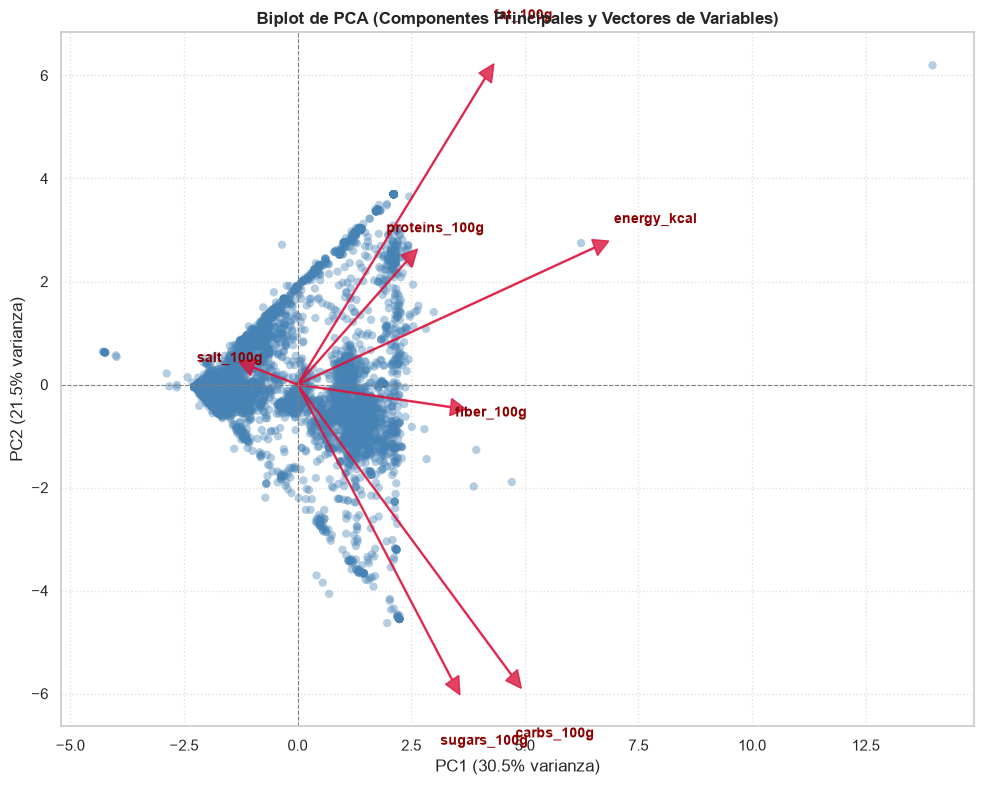

In [76]:
# graficamos para ver mejor las relaciones
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

loadings = pca.components_

plt.figure(figsize=(10, 8))

plt.scatter(
    componentes[:, 0],
    componentes[:, 1],
    alpha=0.4,
    color="steelblue",
    edgecolors="none",
    label="Observaciones",
)

scale_factor = np.max(np.abs(componentes[:, :2])) * 0.8

for i, variable in enumerate(variables_pca):
    x_vec = loadings[0, i] * scale_factor
    y_vec = loadings[1, i] * scale_factor

    plt.arrow(
        0,
        0,
        x_vec,
        y_vec,
        color="crimson",
        alpha=0.8,
        width=scale_factor * 0.002,
        head_width=scale_factor * 0.03,
        head_length=scale_factor * 0.03,
        length_includes_head=True,
    )

    plt.text(
        x_vec * 1.15,
        y_vec * 1.15,
        variable,
        color="darkred",
        weight="bold",
        fontsize=10,
        ha="center",
        va="center",
    )

var_exp = pca.explained_variance_ratio_
plt.xlabel(f"PC1 ({var_exp[0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({var_exp[1]*100:.1f}% varianza)")
plt.title(
    "Biplot de PCA (Componentes Principales y Vectores de Variables)",
    fontsize=12,
    weight="bold",
)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()

plt.show()

### sabemos que al hacer combinaciones lineales, aquellas variables que forman angulos rectos son aquellas que no están relacionadas entre sí. En este caso parece que tenemos 4 dimensiones independientes:
- azucares y carbohidratos
- fibras
- proteinas, energia_kilocalorias y grasas
- sales
(todas cada 100 gramos)
### Las variables dentro de un mismo grupo aportan información redundante, mientras que la ortogonalidad entre grupos demuestra que capturan perfiles nutricionales distintos

## Para este punto parece una buena idea plantearse otra estrategia que nos permita ver más relaciones, como un clusteing. Para ello necesitamos saber cual puede ser un buen número de cluster, por lo que haremos el gráfico del codo

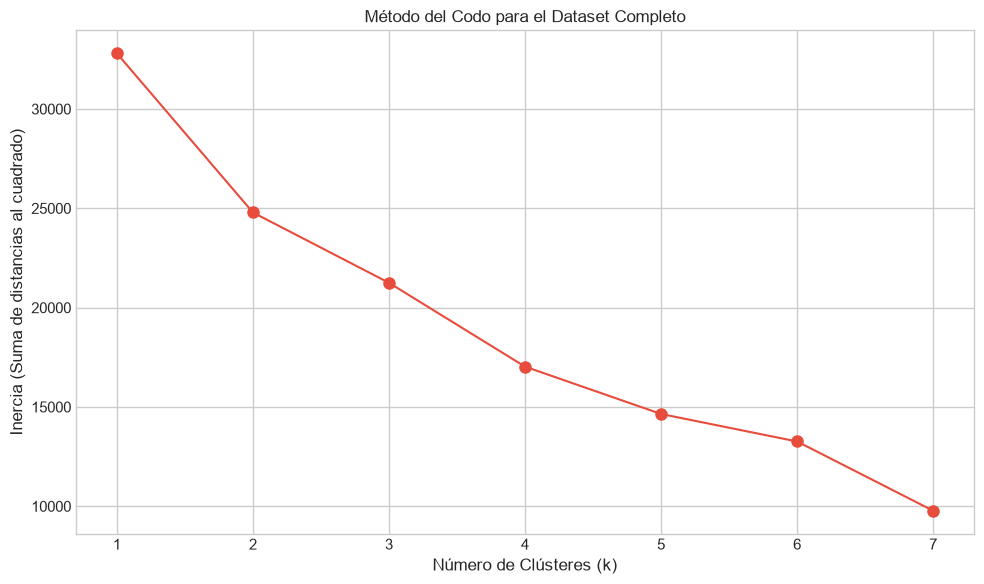

In [83]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inercia = []
rango_k = range(1, 8)

for k in rango_k:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans_temp.fit(X_scaled)
    inercia.append(kmeans_temp.inertia_)

plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(10, 6))
plt.plot(rango_k, inercia, marker='o', linestyle='-', color='#e74c3c', markersize=8)
plt.title('Método del Codo para el Dataset Completo')
plt.xlabel('Número de Clústeres (k)')
plt.ylabel('Inercia (Suma de distancias al cuadrado)')
plt.xticks(rango_k)
plt.tight_layout()
plt.show()

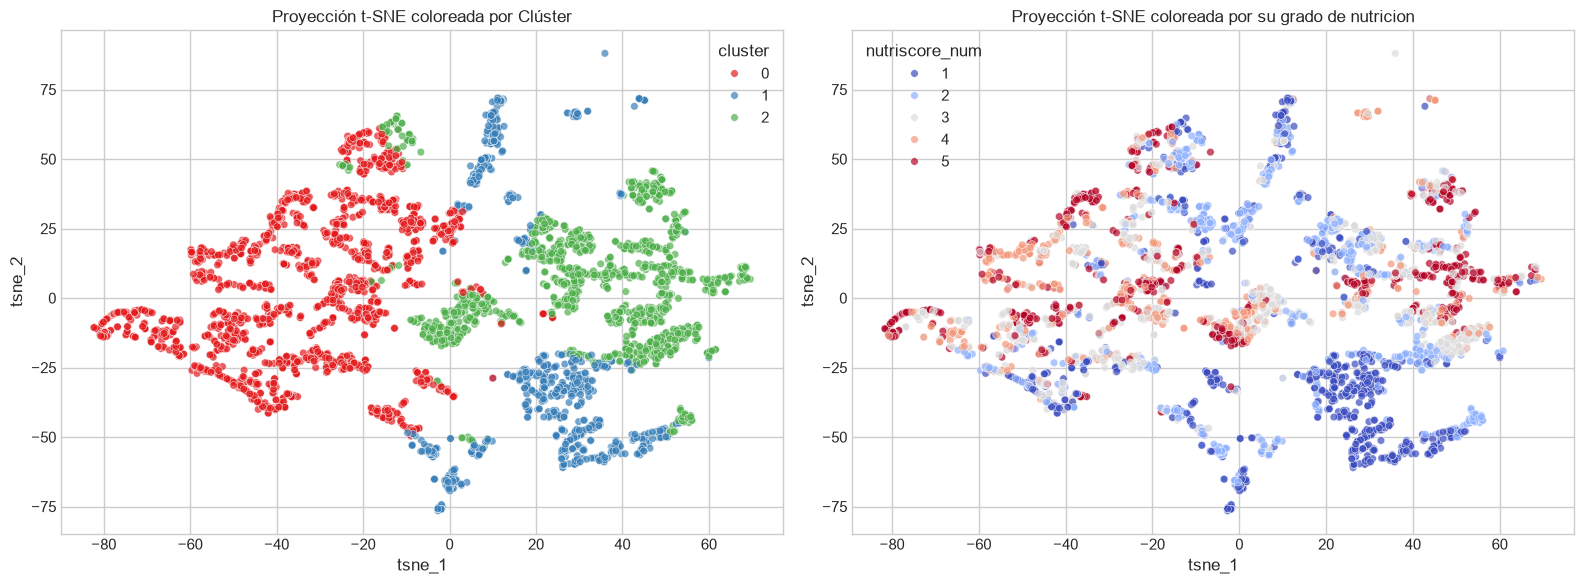

In [85]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

df_model = df.copy()

n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
df_model['cluster'] = kmeans.fit_predict(X_scaled)


tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(X_scaled)

df_model['tsne_1'] = tsne_results[:, 0]
df_model['tsne_2'] = tsne_results[:, 1]


plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(
    data=df_model, x='tsne_1', y='tsne_2', 
    hue='cluster', palette='Set1', alpha=0.7, s=30
)
plt.title('Proyección t-SNE coloreada por Clúster')

plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df_model, x='tsne_1', y='tsne_2', 
    hue='nutriscore_num', palette='coolwarm', alpha=0.7, s=30
)
plt.title('Proyección t-SNE coloreada por su grado de nutricion')
plt.tight_layout()
plt.show()


## En este punto podemos ver que parecieran exitir algunas relaciones entre los diferentes productos y el grado de nutrición de cada uno, como ocurre con el cluster de la esquina inferior derecha (donde vemos un conjunto de alimentos de características similares que son poco nutritivos). Sin embargo, no se nos deja muy en claro cual es su relación, debido a que tenemos productos de muchos tipos. Es por esto que vamos a intentar buscar relaciones entre productos de un mismo tipo usando la columna categoria_macro que generamos en la limpieza

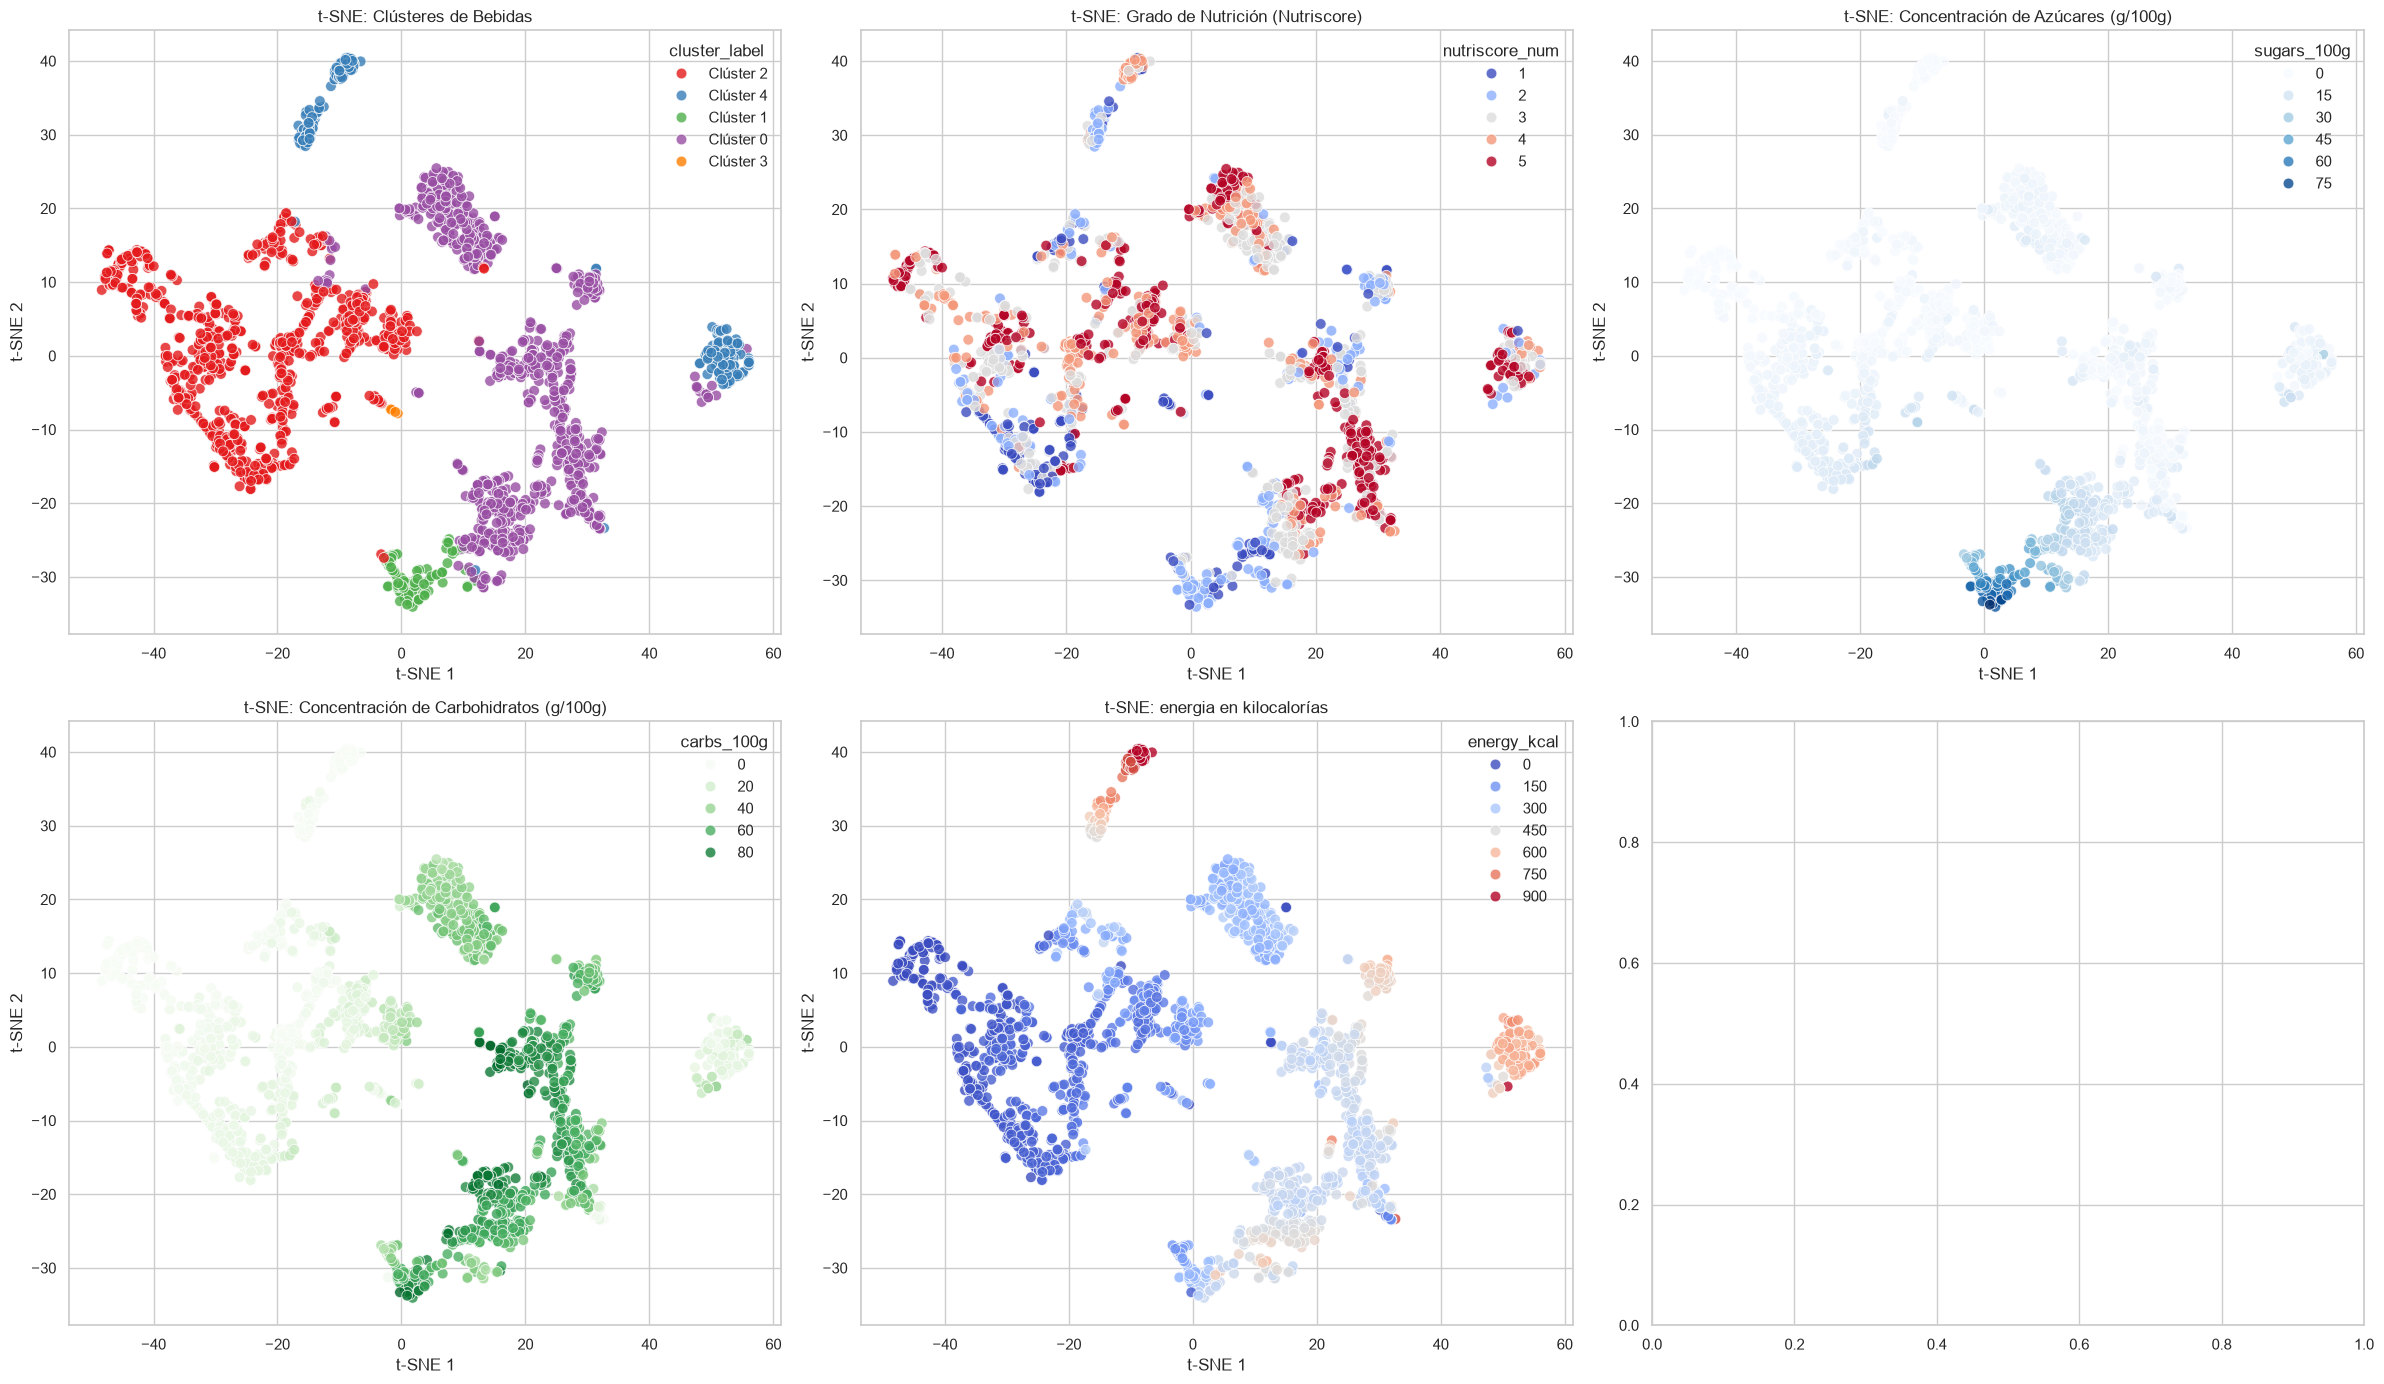

In [ ]:
sns.set_theme(style="whitegrid")

# Variables nutricionales que se usarán para el clustering y t-SNE
features = [
    'energy_kcal', 'fat_100g', 'carbs_100g', 
    'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g'
]

df_bebidas = df[df['categoria_macro'] == 'Bebidas'].copy()

scaler_beb = StandardScaler()
X_bebidas = scaler_beb.fit_transform(df_bebidas[features])

kmeans_beb = KMeans(n_clusters=5, random_state=42, n_init='auto')
df_bebidas['cluster'] = kmeans_beb.fit_predict(X_bebidas)
df_bebidas['cluster_label'] = df_bebidas['cluster'].apply(lambda x: f"Clúster {x}")

tsne_beb = TSNE(n_components=2, random_state=42, perplexity=60)
tsne_beb_res = tsne_beb.fit_transform(X_bebidas)
df_bebidas['tsne_1'] = tsne_beb_res[:, 0]
df_bebidas['tsne_2'] = tsne_beb_res[:, 1]

fig, axes = plt.subplots(2, 3, figsize=(24, 14))

sns.scatterplot(
    data=df_bebidas, x='tsne_1', y='tsne_2', 
    hue='cluster_label', palette='Set1', s=60, alpha=0.8, ax=axes[0, 0]
)
axes[0, 0].set_title('t-SNE: Clústeres de Bebidas')
axes[0, 0].set_xlabel('t-SNE 1')
axes[0, 0].set_ylabel('t-SNE 2')

sns.scatterplot(
    data=df_bebidas, x='tsne_1', y='tsne_2', 
    hue='nutriscore_num', palette='coolwarm', s=60, alpha=0.8, ax=axes[0, 1]
)
axes[0, 1].set_title('t-SNE: Grado de Nutrición (Nutriscore)')
axes[0, 1].set_xlabel('t-SNE 1')
axes[0, 1].set_ylabel('t-SNE 2')

sns.scatterplot(
    data=df_bebidas, x='tsne_1', y='tsne_2', 
    hue='sugars_100g', palette='Blues', s=60, alpha=0.8, ax=axes[0, 2]
)
axes[0, 2].set_title('t-SNE: Concentración de Azúcares (g/100g)')
axes[0, 2].set_xlabel('t-SNE 1')
axes[0, 2].set_ylabel('t-SNE 2')

sns.scatterplot(
    data=df_bebidas, x='tsne_1', y='tsne_2', 
    hue='carbs_100g', palette='Greens', s=60, alpha=0.8, ax=axes[1, 0]
)
axes[1, 0].set_title('t-SNE: Concentración de Carbohidratos (g/100g)')
axes[1, 0].set_xlabel('t-SNE 1')
axes[1, 0].set_ylabel('t-SNE 2')

sns.scatterplot(
    data=df_bebidas, x='tsne_1', y='tsne_2', 
    hue='energy_kcal', palette='coolwarm', s=60, alpha=0.8, ax=axes[1, 1]
)
axes[1, 1].set_title('t-SNE: energia en kilocalorías')
axes[1, 1].set_xlabel('t-SNE 1')
axes[1, 1].set_ylabel('t-SNE 2')

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

### Al hacer esto encontramos dos cluster claramente marcados y relacionados, sin lugar a dudas:
- uno de ellos por su concentración de azucares y carboidratos (que también coincide con uno de los pocos lugares donde )
- y el otro por la cantidad de carbohidratos (aunque este también se mete en el cluster de los azucares)

Procesando categoría: Snacks y Dulces...


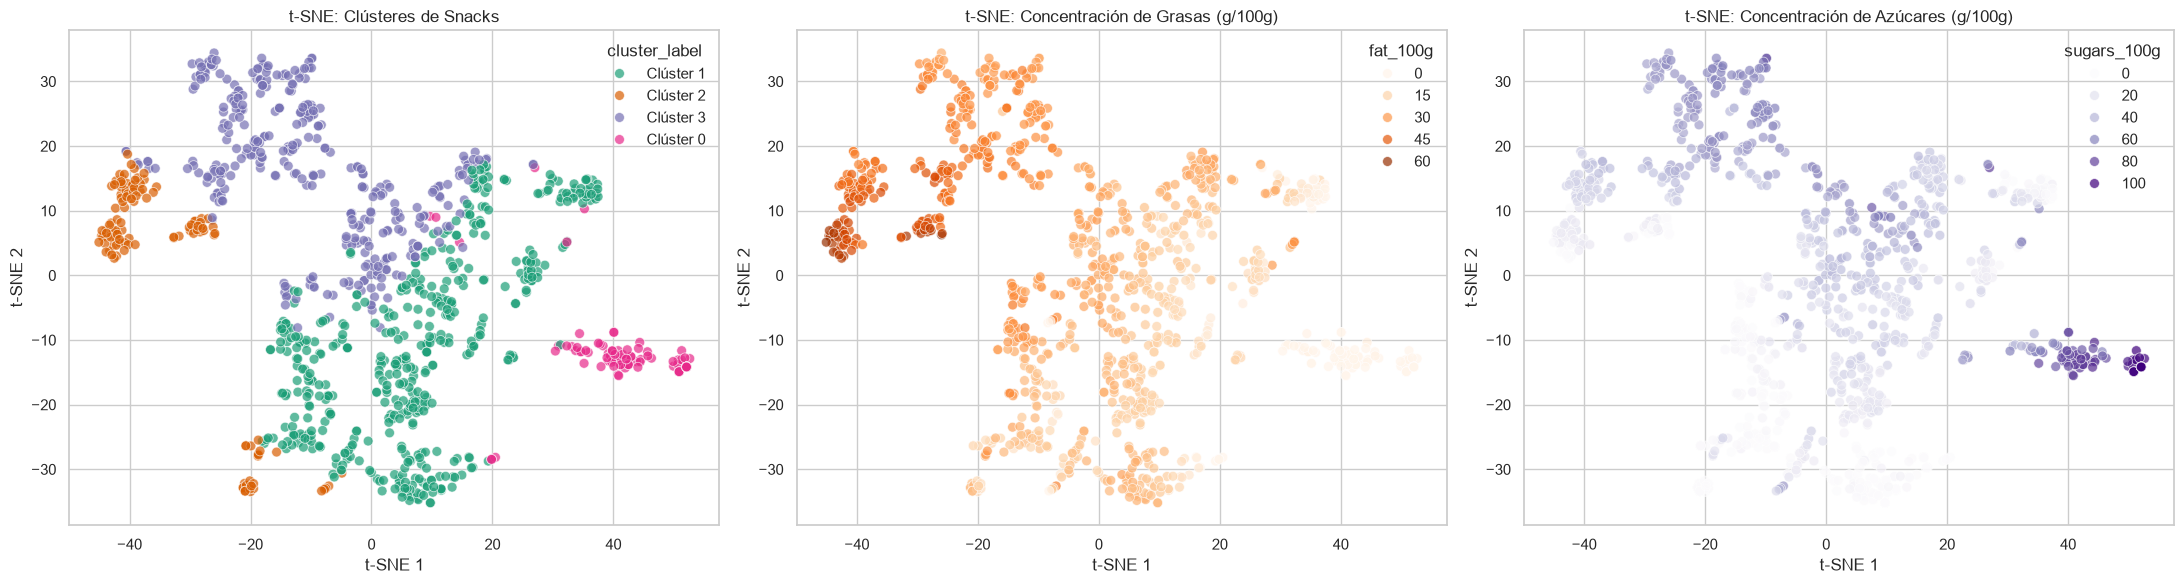

In [63]:
# ==========================================
# CELDA 3: Análisis de Snacks y Dulces
# ==========================================
print("Procesando categoría: Snacks y Dulces...")
df_snacks = df[df['categoria_macro'] == 'Snacks y Dulces'].copy()

# 1. Escalado y Clustering local
scaler_snk = StandardScaler()
X_snacks = scaler_snk.fit_transform(df_snacks[features])

kmeans_snk = KMeans(n_clusters=4, random_state=42, n_init='auto') # Usamos 4 grupos para snacks por mayor variedad
df_snacks['cluster'] = kmeans_snk.fit_predict(X_snacks)
df_snacks['cluster_label'] = df_snacks['cluster'].apply(lambda x: f"Clúster {x}")

# 2. t-SNE local
tsne_snk = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_snk_res = tsne_snk.fit_transform(X_snacks)
df_snacks['tsne_1'] = tsne_snk_res[:, 0]
df_snacks['tsne_2'] = tsne_snk_res[:, 1]

# 3. Visualizaciones (Snacks)
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# Gráfico A: t-SNE coloreado por Clúster (Categórico)
sns.scatterplot(
    data=df_snacks, x='tsne_1', y='tsne_2', 
    hue='cluster_label', palette='Dark2', s=50, alpha=0.7, ax=axes[0]
)
axes[0].set_title('t-SNE: Clústeres de Snacks')
axes[0].set_xlabel('t-SNE 1')
axes[0].set_ylabel('t-SNE 2')

# Gráfico B: t-SNE coloreado por Grasas (Continuo)
sns.scatterplot(
    data=df_snacks, x='tsne_1', y='tsne_2', 
    hue='fat_100g', palette='Oranges', s=50, alpha=0.7, ax=axes[1]
)
axes[1].set_title('t-SNE: Concentración de Grasas (g/100g)')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')

# Gráfico C: t-SNE coloreado por Azúcares (Continuo)
sns.scatterplot(
    data=df_snacks, x='tsne_1', y='tsne_2', 
    hue='sugars_100g', palette='Purples', s=50, alpha=0.7, ax=axes[2]
)
axes[2].set_title('t-SNE: Concentración de Azúcares (g/100g)')
axes[2].set_xlabel('t-SNE 1')
axes[2].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.show()